In [1]:
import os
import mne
import numpy as np

# 作品集根目录
portfolio_dir = r"C:\Users\Administrator\EEG-Analysis-Portfolio"

# 创建 Project 05 目录
project_dir = os.path.join(
    portfolio_dir,
    "Project_05_ERP_Analysis"
)

for folder in ["notebooks", "results", "figures", "reports"]:
    os.makedirs(
        os.path.join(project_dir, folder),
        exist_ok=True
    )

# 读取 Project 03 的 ICA 清理数据
data_path = os.path.join(
    portfolio_dir,
    "Project_03_ICA_Artifact_Removal",
    "results",
    "EEG_ICA_cleaned_raw.fif"
)

raw = mne.io.read_raw_fif(
    data_path,
    preload=True,
    verbose=False
)

print("===== EEG 数据检查 =====")
print("采样率：", raw.info["sfreq"], "Hz")
print("通道数量：", len(raw.ch_names))
print("数据时长：", round(raw.times[-1], 2), "秒")
print("数据形状：", raw.get_data().shape)

print("\n===== Annotation 事件检查 =====")
print(raw.annotations)

print("\n===== Stim 通道检查 =====")
print(mne.pick_types(
    raw.info,
    stim=True,
    exclude=[]
))

===== EEG 数据检查 =====
采样率： 160.0 Hz
通道数量： 64
数据时长： 124.99 秒
数据形状： (64, 20000)

===== Annotation 事件检查 =====
<Annotations | 30 segments: T0 (15), T1 (7), T2 (8)>

===== Stim 通道检查 =====
[]


In [2]:
# 将 Annotation 转换为 MNE Events
events, event_id = mne.events_from_annotations(
    raw,
    verbose=False
)

print("===== 事件编码 =====")
print(event_id)

print("\n===== 事件总数 =====")
print(len(events))

print("\n===== 前10个事件 =====")
print(events[:10])

print("\n===== 各类事件数量 =====")

for name, code in event_id.items():
    count = np.sum(events[:, 2] == code)
    print(f"{name}: {count} 次")

print("\n===== 事件时间（秒） =====")
print(events[:10, 0] / raw.info["sfreq"])

===== 事件编码 =====
{np.str_('T0'): 1, np.str_('T1'): 2, np.str_('T2'): 3}

===== 事件总数 =====
30

===== 前10个事件 =====
[[   0    0    1]
 [ 672    0    3]
 [1328    0    1]
 [2000    0    2]
 [2656    0    1]
 [3328    0    2]
 [3984    0    1]
 [4656    0    3]
 [5312    0    1]
 [5984    0    2]]

===== 各类事件数量 =====
T0: 15 次
T1: 7 次
T2: 8 次

===== 事件时间（秒） =====
[ 0.   4.2  8.3 12.5 16.6 20.8 24.9 29.1 33.2 37.4]


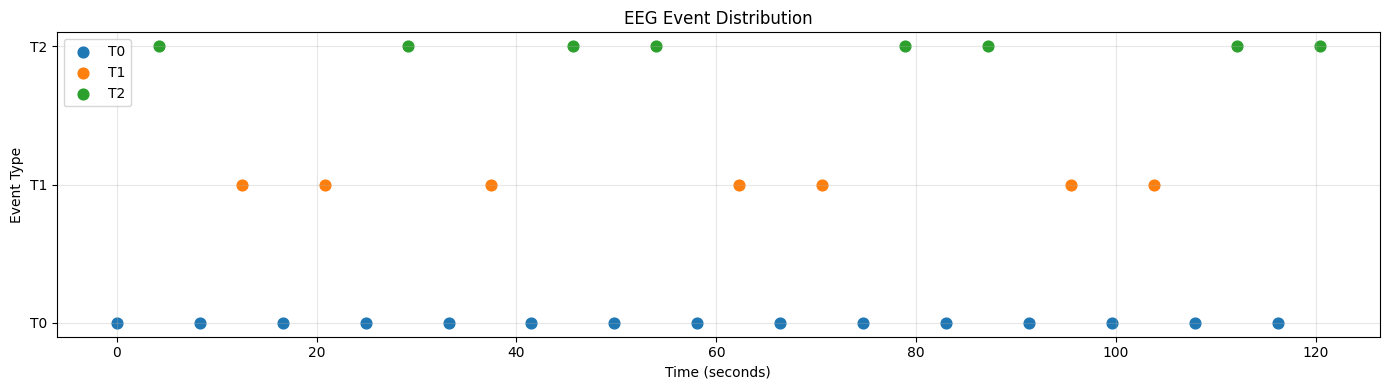

In [3]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 4))

for event_name, event_code in event_id.items():
    event_times = (
        events[events[:, 2] == event_code, 0]
        / raw.info["sfreq"]
    )

    plt.scatter(
        event_times,
        [event_code] * len(event_times),
        label=event_name,
        s=60
    )

plt.yticks(
    list(event_id.values()),
    list(event_id.keys())
)

plt.xlabel("Time (seconds)")
plt.ylabel("Event Type")
plt.title("EEG Event Distribution")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

In [4]:
# 查看 EEG 原始数据中的事件注释信息

annotations = raw.annotations

print("===== Annotation 信息 =====")
print("注释总数：", len(annotations))

for i in range(min(10, len(annotations))):
    print(
        f"第{i+1}条："
        f"描述={annotations.description[i]}, "
        f"开始时间={annotations.onset[i]:.3f}s, "
        f"持续时间={annotations.duration[i]:.3f}s"
    )

print("\n===== 所有事件类型 =====")
for name in np.unique(annotations.description):
    count = np.sum(annotations.description == name)
    print(f"{name}: {count} 次")

===== Annotation 信息 =====
注释总数： 30
第1条：描述=T0, 开始时间=0.000s, 持续时间=4.200s
第2条：描述=T2, 开始时间=4.200s, 持续时间=4.100s
第3条：描述=T0, 开始时间=8.300s, 持续时间=4.200s
第4条：描述=T1, 开始时间=12.500s, 持续时间=4.100s
第5条：描述=T0, 开始时间=16.600s, 持续时间=4.200s
第6条：描述=T1, 开始时间=20.800s, 持续时间=4.100s
第7条：描述=T0, 开始时间=24.900s, 持续时间=4.200s
第8条：描述=T2, 开始时间=29.100s, 持续时间=4.100s
第9条：描述=T0, 开始时间=33.200s, 持续时间=4.200s
第10条：描述=T1, 开始时间=37.400s, 持续时间=4.100s

===== 所有事件类型 =====
T0: 15 次
T1: 7 次
T2: 8 次


In [5]:
# 检查运动相关脑区通道名称

print("===== 运动相关通道 =====")

for ch in raw.ch_names:
    if ch.lower().startswith(("c3", "cz", "c4", "cp3", "cpz", "cp4")):
        print(ch)

===== 运动相关通道 =====
C3
Cz
C4
CP3
CPz
CP4


In [6]:
# 提取运动想象事件

events, event_id = mne.events_from_annotations(
    raw,
    verbose=False
)

print("===== 事件编码 =====")
print(event_id)

print("\n===== 事件数量 =====")

for name, code in event_id.items():
    count = np.sum(events[:, 2] == code)
    print(f"{name}: {count} 次")

print("\n===== 前10个事件 =====")
print(events[:10])

===== 事件编码 =====
{np.str_('T0'): 1, np.str_('T1'): 2, np.str_('T2'): 3}

===== 事件数量 =====
T0: 15 次
T1: 7 次
T2: 8 次

===== 前10个事件 =====
[[   0    0    1]
 [ 672    0    3]
 [1328    0    1]
 [2000    0    2]
 [2656    0    1]
 [3328    0    2]
 [3984    0    1]
 [4656    0    3]
 [5312    0    1]
 [5984    0    2]]


In [7]:
# 创建运动想象任务区段 Epochs

motor_channels = ["C3", "Cz", "C4", "CP3", "CPz", "CP4"]

epochs = mne.Epochs(
    raw,
    events,
    event_id=event_id,
    tmin=0,
    tmax=4.0,
    baseline=None,
    picks=motor_channels,
    preload=True,
    reject_by_annotation=True,
    verbose=False
)

print("===== Epochs 创建结果 =====")
print("区段数据形状：", epochs.get_data().shape)
print("通道：", epochs.ch_names)
print("采样率：", epochs.info["sfreq"])

print("\n===== 各类区段数量 =====")
for name in event_id:
    print(f"{name}: {len(epochs[name])} 个")

===== Epochs 创建结果 =====
区段数据形状： (30, 6, 641)
通道： ['C3', 'Cz', 'C4', 'CP3', 'CPz', 'CP4']
采样率： 160.0

===== 各类区段数量 =====
T0: 15 个
T1: 7 个
T2: 8 个


In [8]:
# 计算每个任务区段的 μ 波和 β 波功率

import pandas as pd

data = epochs.get_data()
sfreq = epochs.info["sfreq"]

results = []

for i, epoch_data in enumerate(data):

    for ch_idx, ch_name in enumerate(epochs.ch_names):

        signal = epoch_data[ch_idx]

        psd, freqs = mne.time_frequency.psd_array_welch(
            signal,
            sfreq=sfreq,
            fmin=8,
            fmax=30,
            n_per_seg=320,
            n_fft=512,
            n_overlap=160,
            verbose=False
        )

        mu_power = psd[
            (freqs >= 8) & (freqs < 13)
        ].mean()

        beta_power = psd[
            (freqs >= 13) & (freqs <= 30)
        ].mean()

        results.append({
            "Epoch": i,
            "Condition": epochs.events[i, 2],
            "Channel": ch_name,
            "Mu_Power": mu_power,
            "Beta_Power": beta_power
        })

power_df = pd.DataFrame(results)

condition_map = {
    1: "T0_Rest",
    2: "T1_Hands",
    3: "T2_Feet"
}

power_df["Condition"] = power_df["Condition"].map(condition_map)

print("===== 频段功率结果 =====")
print(power_df.head(10))

print("\n数据表形状：", power_df.shape)

===== 频段功率结果 =====
   Epoch Condition Channel      Mu_Power    Beta_Power
0      0   T0_Rest      C3  5.041441e-12  2.272031e-12
1      0   T0_Rest      Cz  5.604182e-12  1.813135e-12
2      0   T0_Rest      C4  5.524883e-12  2.038147e-12
3      0   T0_Rest     CP3  5.540382e-12  1.960677e-12
4      0   T0_Rest     CPz  5.908571e-12  1.806919e-12
5      0   T0_Rest     CP4  6.912280e-12  2.399366e-12
6      1   T2_Feet      C3  1.559417e-11  2.271739e-12
7      1   T2_Feet      Cz  5.446933e-12  3.149328e-12
8      1   T2_Feet      C4  1.104306e-11  1.692950e-12
9      1   T2_Feet     CP3  6.003729e-12  1.745590e-12

数据表形状： (180, 5)


In [9]:
# 按任务和通道计算平均 μ / β 功率

summary_df = (
    power_df
    .groupby(["Condition", "Channel"])[
        ["Mu_Power", "Beta_Power"]
    ]
    .mean()
    .reset_index()
)

print("===== 三种任务的平均频段功率 =====")

display(
    summary_df.round(13)
)

===== 三种任务的平均频段功率 =====


,Condition,Channel,Mu_Power,Beta_Power
0,T0_Rest,C3,1.160000e-11,2.500000e-12
1,T0_Rest,C4,9.900000e-12,2.500000e-12
2,T0_Rest,CP3,7.700000e-12,2.400000e-12
3,T0_Rest,CP4,1.000000e-11,2.700000e-12
4,T0_Rest,CPz,5.200000e-12,1.800000e-12
5,T0_Rest,Cz,5.700000e-12,2.700000e-12
6,T1_Hands,C3,4.300000e-12,2.200000e-12
7,T1_Hands,C4,4.200000e-12,2.300000e-12
8,T1_Hands,CP3,5.300000e-12,2.100000e-12
9,T1_Hands,CP4,6.700000e-12,2.300000e-12


In [10]:
# 计算相对于休息状态的 μ / β 功率变化百分比

erd_rows = []

for ch in summary_df["Channel"].unique():

    channel_data = summary_df[
        summary_df["Channel"] == ch
    ].set_index("Condition")

    rest = channel_data.loc["T0_Rest"]

    for condition in ["T1_Hands", "T2_Feet"]:

        task = channel_data.loc[condition]

        mu_change = (
            (task["Mu_Power"] - rest["Mu_Power"])
            / rest["Mu_Power"] * 100
        )

        beta_change = (
            (task["Beta_Power"] - rest["Beta_Power"])
            / rest["Beta_Power"] * 100
        )

        erd_rows.append({
            "Condition": condition,
            "Channel": ch,
            "Mu_change_%": mu_change,
            "Beta_change_%": beta_change
        })

erd_df = pd.DataFrame(erd_rows)

print("===== 相对休息状态的功率变化 =====")
display(erd_df.round(2))

===== 相对休息状态的功率变化 =====


,Condition,Channel,Mu_change_%,Beta_change_%
0,T1_Hands,C3,-62.55,-13.08
1,T2_Feet,C3,29.68,1.63
2,T1_Hands,C4,-57.69,-9.72
3,T2_Feet,C4,9.08,-2.65
4,T1_Hands,CP3,-31.56,-12.83
5,T2_Feet,CP3,8.72,-6.78
6,T1_Hands,CP4,-32.93,-14.17
7,T2_Feet,CP4,-37.29,-20.42
8,T1_Hands,CPz,7.21,21.15
9,T2_Feet,CPz,-15.16,13.05


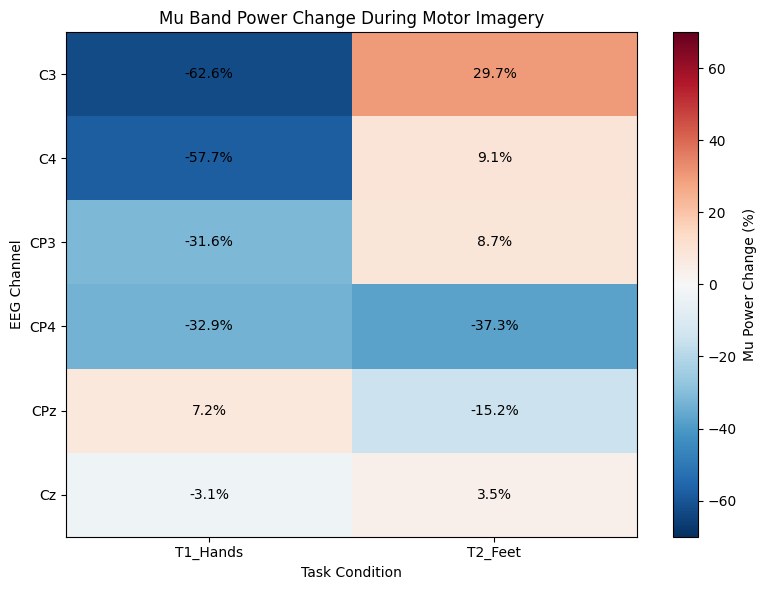

In [11]:
# 绘制 μ 波功率变化热图

import matplotlib.pyplot as plt
import numpy as np

mu_matrix = erd_df.pivot(
    index="Channel",
    columns="Condition",
    values="Mu_change_%"
)

plt.figure(figsize=(8, 6))

plt.imshow(
    mu_matrix.values,
    aspect="auto",
    cmap="RdBu_r",
    vmin=-70,
    vmax=70
)

plt.colorbar(label="Mu Power Change (%)")

plt.xticks(
    range(len(mu_matrix.columns)),
    mu_matrix.columns
)

plt.yticks(
    range(len(mu_matrix.index)),
    mu_matrix.index
)

plt.title("Mu Band Power Change During Motor Imagery")
plt.xlabel("Task Condition")
plt.ylabel("EEG Channel")

for i in range(mu_matrix.shape[0]):
    for j in range(mu_matrix.shape[1]):
        plt.text(
            j, i,
            f"{mu_matrix.iloc[i, j]:.1f}%",
            ha="center",
            va="center"
        )

plt.tight_layout()
plt.show()

In [12]:
# 检查 Epoch 时间范围

print("===== Epoch 时间信息 =====")
print("起始时间：", epochs.times[0], "秒")
print("结束时间：", epochs.times[-1], "秒")
print("采样点数：", len(epochs.times))
print("采样率：", epochs.info["sfreq"], "Hz")

print("\n===== 时间轴前10个采样点 =====")
print(epochs.times[:10])

===== Epoch 时间信息 =====
起始时间： 0.0 秒
结束时间： 4.0 秒
采样点数： 641
采样率： 160.0 Hz

===== 时间轴前10个采样点 =====
[0.      0.00625 0.0125  0.01875 0.025   0.03125 0.0375  0.04375 0.05
 0.05625]


In [13]:
# 计算 C3、Cz、C4 的 μ 波滑动窗口功率

from scipy.signal import welch

motor_channels = ["C3", "Cz", "C4"]

sfreq = epochs.info["sfreq"]
epoch_data = epochs.get_data(picks=motor_channels)

window_samples = int(1.0 * sfreq)
step_samples = int(0.5 * sfreq)

time_results = []

for epoch_idx, epoch_data_item in enumerate(epoch_data):

    condition_code = epochs.events[epoch_idx, 2]

    condition_name = {
        1: "T0_Rest",
        2: "T1_Hands",
        3: "T2_Feet"
    }[condition_code]

    for ch_idx, ch_name in enumerate(motor_channels):

        signal = epoch_data_item[ch_idx]

        for start in range(
            0,
            len(signal) - window_samples + 1,
            step_samples
        ):

            segment = signal[
                start:start + window_samples
            ]

            freqs, psd = welch(
                segment,
                fs=sfreq,
                nperseg=window_samples,
                nfft=256
            )

            mu_power = psd[
                (freqs >= 8) & (freqs < 13)
            ].mean()

            time_results.append({
                "Epoch": epoch_idx,
                "Condition": condition_name,
                "Channel": ch_name,
                "Time": start / sfreq,
                "Mu_Power": mu_power
            })

time_df = pd.DataFrame(time_results)

print("===== 滑动窗口计算结果 =====")
print(time_df.head(12))

print("\n数据表形状：", time_df.shape)
print("时间窗口：", sorted(time_df["Time"].unique()))

===== 滑动窗口计算结果 =====
    Epoch Condition Channel  Time      Mu_Power
0       0   T0_Rest      C3   0.0  4.643610e-12
1       0   T0_Rest      C3   0.5  1.175110e-11
2       0   T0_Rest      C3   1.0  5.364628e-12
3       0   T0_Rest      C3   1.5  6.996836e-12
4       0   T0_Rest      C3   2.0  2.051630e-12
5       0   T0_Rest      C3   2.5  4.262943e-13
6       0   T0_Rest      C3   3.0  2.064663e-12
7       0   T0_Rest      Cz   0.0  1.328543e-11
8       0   T0_Rest      Cz   0.5  6.090697e-12
9       0   T0_Rest      Cz   1.0  2.516518e-12
10      0   T0_Rest      Cz   1.5  1.227082e-11
11      0   T0_Rest      Cz   2.0  1.443112e-12

数据表形状： (630, 5)
时间窗口： [np.float64(0.0), np.float64(0.5), np.float64(1.0), np.float64(1.5), np.float64(2.0), np.float64(2.5), np.float64(3.0)]


In [14]:
# 计算每个时间窗口相对于 T0 休息状态的 μ 波变化

time_summary = (
    time_df
    .groupby(["Condition", "Channel", "Time"])["Mu_Power"]
    .mean()
    .reset_index()
)

erd_time_rows = []

for ch in ["C3", "Cz", "C4"]:

    for t in sorted(time_df["Time"].unique()):

        rest = time_summary[
            (time_summary["Condition"] == "T0_Rest") &
            (time_summary["Channel"] == ch) &
            (time_summary["Time"] == t)
        ]["Mu_Power"].iloc[0]

        for condition in ["T1_Hands", "T2_Feet"]:

            task = time_summary[
                (time_summary["Condition"] == condition) &
                (time_summary["Channel"] == ch) &
                (time_summary["Time"] == t)
            ]["Mu_Power"].iloc[0]

            change = (task - rest) / rest * 100

            erd_time_rows.append({
                "Condition": condition,
                "Channel": ch,
                "Time": t,
                "Mu_Change_%": change
            })

erd_time_df = pd.DataFrame(erd_time_rows)

print("===== 时间变化结果 =====")
display(erd_time_df.round(2))

print("\n数据表形状：", erd_time_df.shape)

===== 时间变化结果 =====


,Condition,Channel,Time,Mu_Change_%
0,T1_Hands,C3,0.0,-33.76
1,T2_Feet,C3,0.0,2.71
2,T1_Hands,C3,0.5,-65.54
3,T2_Feet,C3,0.5,-3.01
4,T1_Hands,C3,1.0,-54.93
5,T2_Feet,C3,1.0,23.01
6,T1_Hands,C3,1.5,-61.11
7,T2_Feet,C3,1.5,51.30
8,T1_Hands,C3,2.0,-75.71
9,T2_Feet,C3,2.0,62.50



数据表形状： (42, 4)


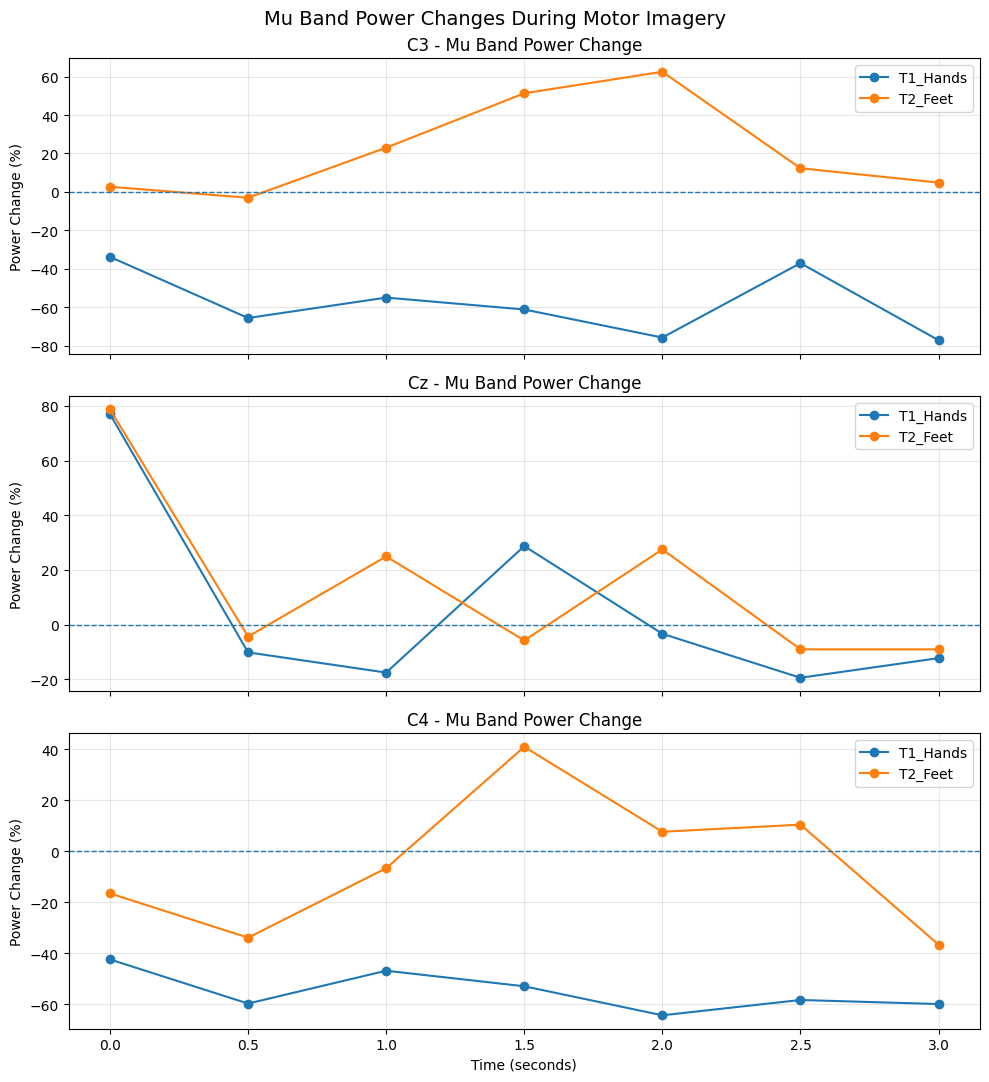

In [15]:
# 绘制三个运动相关通道的 μ 波时间变化曲线

import matplotlib.pyplot as plt

channels = ["C3", "Cz", "C4"]

fig, axes = plt.subplots(
    3, 1,
    figsize=(10, 11),
    sharex=True
)

for ax, ch in zip(axes, channels):

    channel_data = erd_time_df[
        erd_time_df["Channel"] == ch
    ]

    for condition in ["T1_Hands", "T2_Feet"]:

        plot_data = channel_data[
            channel_data["Condition"] == condition
        ]

        ax.plot(
            plot_data["Time"],
            plot_data["Mu_Change_%"],
            marker="o",
            label=condition
        )

    ax.axhline(
        0,
        linestyle="--",
        linewidth=1
    )

    ax.set_title(f"{ch} - Mu Band Power Change")
    ax.set_ylabel("Power Change (%)")
    ax.grid(alpha=0.3)
    ax.legend()

axes[-1].set_xlabel("Time (seconds)")

plt.suptitle(
    "Mu Band Power Changes During Motor Imagery",
    fontsize=14
)

plt.tight_layout()
plt.show()

In [16]:
# 计算 C3、Cz、C4 的 β 波滑动窗口功率

beta_time_rows = []

for epoch_idx, epoch_data_item in enumerate(epoch_data):

    condition_code = epochs.events[epoch_idx, 2]

    condition_name = {
        1: "T0_Rest",
        2: "T1_Hands",
        3: "T2_Feet"
    }[condition_code]

    for ch_idx, ch_name in enumerate(motor_channels):

        signal = epoch_data_item[ch_idx]

        for start in range(
            0,
            len(signal) - window_samples + 1,
            step_samples
        ):

            segment = signal[
                start:start + window_samples
            ]

            freqs, psd = welch(
                segment,
                fs=sfreq,
                nperseg=window_samples,
                nfft=256
            )

            beta_power = psd[
                (freqs >= 13) & (freqs <= 30)
            ].mean()

            beta_time_rows.append({
                "Epoch": epoch_idx,
                "Condition": condition_name,
                "Channel": ch_name,
                "Time": start / sfreq,
                "Beta_Power": beta_power
            })

beta_time_df = pd.DataFrame(beta_time_rows)

print("===== β 波滑动窗口结果 =====")
print(beta_time_df.head(12))
print("\n数据表形状：", beta_time_df.shape)

===== β 波滑动窗口结果 =====
    Epoch Condition Channel  Time    Beta_Power
0       0   T0_Rest      C3   0.0  3.173179e-12
1       0   T0_Rest      C3   0.5  1.971596e-12
2       0   T0_Rest      C3   1.0  2.304749e-12
3       0   T0_Rest      C3   1.5  3.019227e-12
4       0   T0_Rest      C3   2.0  1.254938e-12
5       0   T0_Rest      C3   2.5  2.553444e-12
6       0   T0_Rest      C3   3.0  1.243651e-12
7       0   T0_Rest      Cz   0.0  2.489863e-12
8       0   T0_Rest      Cz   0.5  1.962744e-12
9       0   T0_Rest      Cz   1.0  1.431999e-12
10      0   T0_Rest      Cz   1.5  1.365100e-12
11      0   T0_Rest      Cz   2.0  2.333327e-12

数据表形状： (630, 5)


In [17]:
# 计算 β 波相对于 T0 休息状态的功率变化

beta_summary = (
    beta_time_df
    .groupby(["Condition", "Channel", "Time"])["Beta_Power"]
    .mean()
    .reset_index()
)

beta_erd_rows = []

for ch in ["C3", "Cz", "C4"]:

    for t in sorted(beta_time_df["Time"].unique()):

        rest = beta_summary[
            (beta_summary["Condition"] == "T0_Rest") &
            (beta_summary["Channel"] == ch) &
            (beta_summary["Time"] == t)
        ]["Beta_Power"].iloc[0]

        for condition in ["T1_Hands", "T2_Feet"]:

            task = beta_summary[
                (beta_summary["Condition"] == condition) &
                (beta_summary["Channel"] == ch) &
                (beta_summary["Time"] == t)
            ]["Beta_Power"].iloc[0]

            change = (task - rest) / rest * 100

            beta_erd_rows.append({
                "Condition": condition,
                "Channel": ch,
                "Time": t,
                "Beta_Change_%": change
            })

beta_erd_time_df = pd.DataFrame(beta_erd_rows)

print("===== β 波时间变化结果 =====")
display(beta_erd_time_df.round(2))

print("\n数据表形状：", beta_erd_time_df.shape)

===== β 波时间变化结果 =====


,Condition,Channel,Time,Beta_Change_%
0,T1_Hands,C3,0.0,-35.26
1,T2_Feet,C3,0.0,18.50
2,T1_Hands,C3,0.5,-36.43
3,T2_Feet,C3,0.5,-21.30
4,T1_Hands,C3,1.0,-17.14
5,T2_Feet,C3,1.0,41.14
6,T1_Hands,C3,1.5,-19.84
7,T2_Feet,C3,1.5,10.91
8,T1_Hands,C3,2.0,-31.18
9,T2_Feet,C3,2.0,20.17



数据表形状： (42, 4)


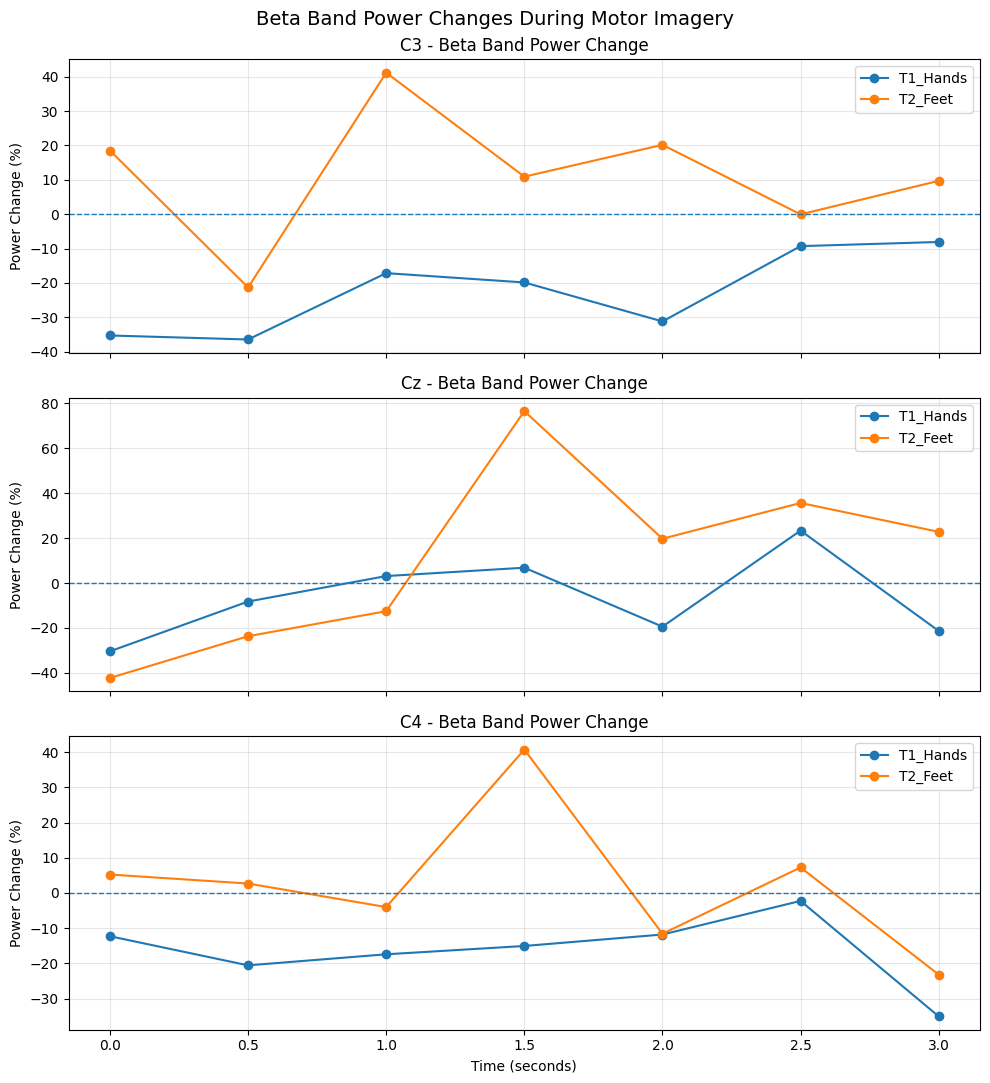

In [18]:
# 绘制 C3、Cz、C4 的 β 波时间变化曲线

import matplotlib.pyplot as plt

channels = ["C3", "Cz", "C4"]

fig, axes = plt.subplots(
    3, 1,
    figsize=(10, 11),
    sharex=True
)

for ax, ch in zip(axes, channels):

    channel_data = beta_erd_time_df[
        beta_erd_time_df["Channel"] == ch
    ]

    for condition in ["T1_Hands", "T2_Feet"]:

        plot_data = channel_data[
            channel_data["Condition"] == condition
        ]

        ax.plot(
            plot_data["Time"],
            plot_data["Beta_Change_%"],
            marker="o",
            label=condition
        )

    ax.axhline(
        0,
        linestyle="--",
        linewidth=1
    )

    ax.set_title(f"{ch} - Beta Band Power Change")
    ax.set_ylabel("Power Change (%)")
    ax.grid(alpha=0.3)
    ax.legend()

axes[-1].set_xlabel("Time (seconds)")

plt.suptitle(
    "Beta Band Power Changes During Motor Imagery",
    fontsize=14
)

plt.tight_layout()
plt.show()

In [19]:
# 合并 Mu 和 Beta 时间变化结果

combined_time_df = pd.merge(
    erd_time_df,
    beta_erd_time_df,
    on=["Condition", "Channel", "Time"],
    how="inner"
)

combined_time_df = combined_time_df.sort_values(
    ["Channel", "Condition", "Time"]
).reset_index(drop=True)

print("===== Mu / Beta 综合结果 =====")
display(combined_time_df.round(2))

print("\n数据表形状：", combined_time_df.shape)

print("\n各通道数据量：")
print(combined_time_df.groupby("Channel").size())

===== Mu / Beta 综合结果 =====


,Condition,Channel,Time,Mu_Change_%,Beta_Change_%
0,T1_Hands,C3,0.0,-33.76,-35.26
1,T1_Hands,C3,0.5,-65.54,-36.43
2,T1_Hands,C3,1.0,-54.93,-17.14
3,T1_Hands,C3,1.5,-61.11,-19.84
4,T1_Hands,C3,2.0,-75.71,-31.18
5,T1_Hands,C3,2.5,-37.02,-9.29
6,T1_Hands,C3,3.0,-77.11,-8.08
7,T2_Feet,C3,0.0,2.71,18.50
8,T2_Feet,C3,0.5,-3.01,-21.30
9,T2_Feet,C3,1.0,23.01,41.14



数据表形状： (42, 5)

各通道数据量：
Channel
C3    14
C4    14
Cz    14
dtype: int64


In [20]:
# 保存 Mu / Beta 综合时间变化结果

import os

results_dir = os.path.join(project_dir, "results")
os.makedirs(results_dir, exist_ok=True)

output_path = os.path.join(
    results_dir,
    "EEG_Mu_Beta_Time_Changes.csv"
)

combined_time_df.to_csv(
    output_path,
    index=False,
    encoding="utf-8-sig"
)

print("文件保存成功：")
print(output_path)

print("\n文件大小：")
print(f"{os.path.getsize(output_path) / 1024:.2f} KB")

文件保存成功：
C:\Users\Administrator\EEG-Analysis-Portfolio\Project_05_ERP_Analysis\results\EEG_Mu_Beta_Time_Changes.csv

文件大小：
2.29 KB


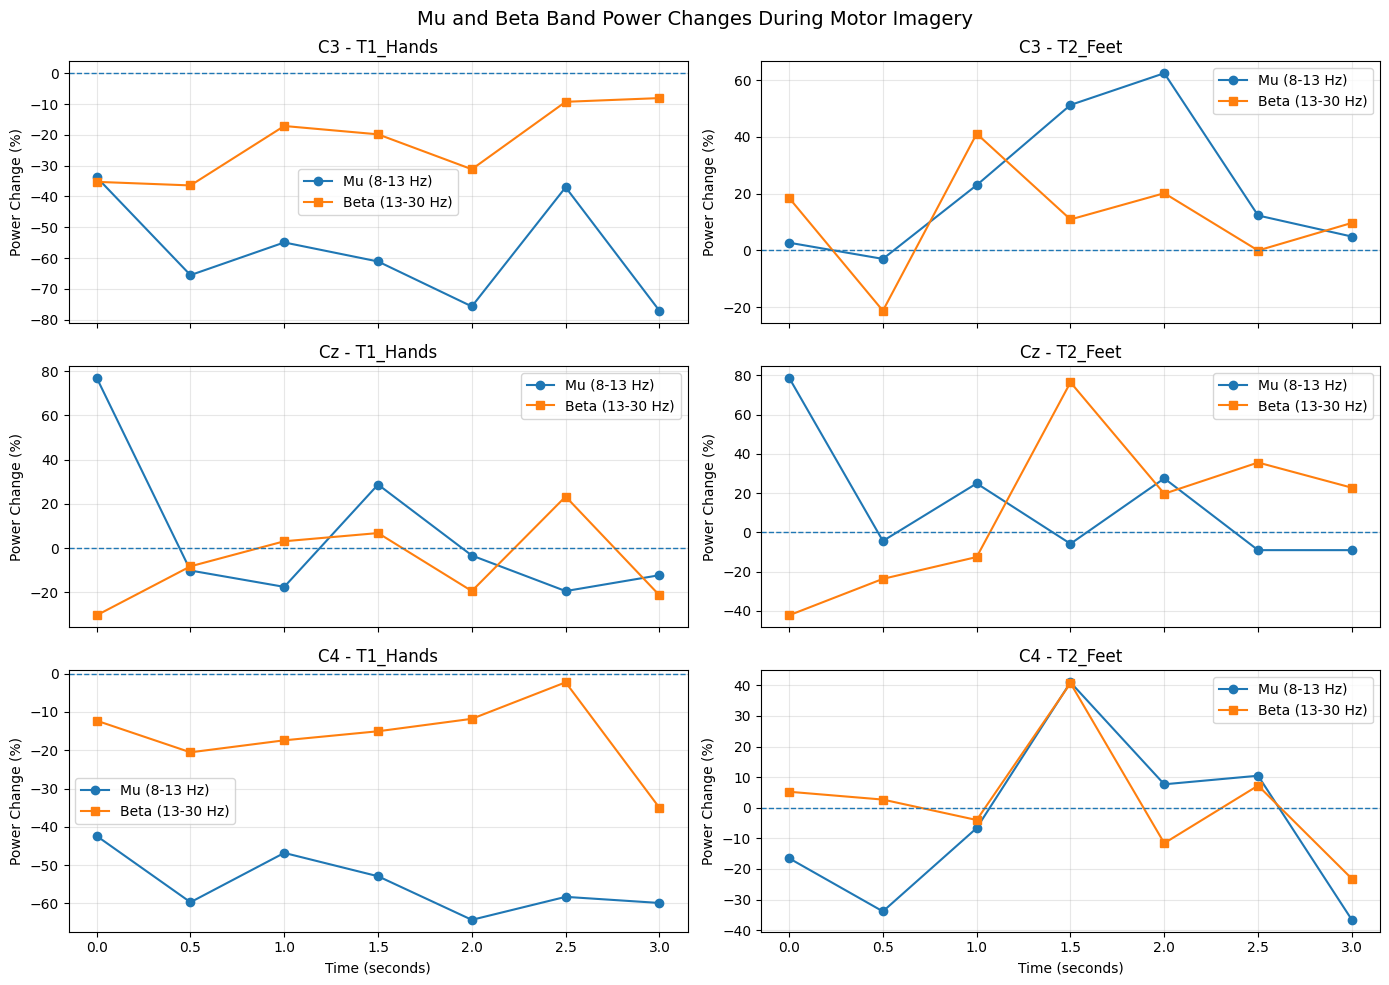

综合对比图保存成功：
C:\Users\Administrator\EEG-Analysis-Portfolio\Project_05_ERP_Analysis\figures\EEG_Mu_Beta_Time_Comparison.png


In [21]:
# 绘制 Mu / Beta 综合时间变化图并保存

import matplotlib.pyplot as plt
import os

channels = ["C3", "Cz", "C4"]
conditions = ["T1_Hands", "T2_Feet"]

fig, axes = plt.subplots(
    3, 2,
    figsize=(14, 10),
    sharex=True
)

for row, ch in enumerate(channels):

    for col, condition in enumerate(conditions):

        ax = axes[row, col]

        data = combined_time_df[
            (combined_time_df["Channel"] == ch) &
            (combined_time_df["Condition"] == condition)
        ].sort_values("Time")

        ax.plot(
            data["Time"],
            data["Mu_Change_%"],
            marker="o",
            label="Mu (8-13 Hz)"
        )

        ax.plot(
            data["Time"],
            data["Beta_Change_%"],
            marker="s",
            label="Beta (13-30 Hz)"
        )

        ax.axhline(0, linestyle="--", linewidth=1)

        ax.set_title(f"{ch} - {condition}")
        ax.set_ylabel("Power Change (%)")
        ax.grid(alpha=0.3)
        ax.legend()

for ax in axes[-1, :]:
    ax.set_xlabel("Time (seconds)")

fig.suptitle(
    "Mu and Beta Band Power Changes During Motor Imagery",
    fontsize=14
)

plt.tight_layout()

figure_path = os.path.join(
    project_dir,
    "figures",
    "EEG_Mu_Beta_Time_Comparison.png"
)

os.makedirs(os.path.dirname(figure_path), exist_ok=True)

plt.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("综合对比图保存成功：")
print(figure_path)

In [22]:
# 创建 Project 05 分析报告

report_dir = os.path.join(project_dir, "reports")
os.makedirs(report_dir, exist_ok=True)

report_path = os.path.join(
    report_dir,
    "EEG_Motor_Imagery_Analysis_Report.md"
)

report_text = """
# EEG Motor Imagery Analysis Report

## 1. Project Overview

This project explores EEG frequency-band power changes
under different motor imagery event conditions.

The analysis focuses on:
- C3, Cz, C4
- Mu band: 8–13 Hz
- Beta band: 13–30 Hz
- T1 and T2 event conditions

## 2. Dataset Information

- Source file: S001R06.edf
- Sampling frequency: 160 Hz
- EEG channels: 64
- Duration: approximately 125 seconds
- Event annotations: T0, T1, T2
- Data used for analysis: ICA-cleaned EEG

The exact experimental meaning of T0, T1 and T2
should be confirmed against the original dataset documentation.

## 3. Analysis Workflow

1. Load ICA-cleaned EEG data.
2. Extract event annotations.
3. Create event-related epochs.
4. Select C3, Cz and C4 channels.
5. Calculate Mu and Beta band power.
6. Apply sliding-window analysis.
7. Compare task-condition averages with T0 averages.
8. Visualize temporal power changes.

## 4. Main Observations

Under T1, C3 and C4 show decreases in both Mu and Beta
band power relative to the T0 condition averages.

Under T2, the temporal patterns are more variable.

These are exploratory observations and have not been
validated through inferential statistical testing.

## 5. Important Limitations

- The exact event definitions require dataset documentation.
- The number of epochs is limited.
- T0 is a separate condition average, not a trial-specific
  pre-stimulus baseline.
- The analysis uses ICA-cleaned data rather than the original
  unprocessed recording.
- No classification model or independent test set was evaluated.
- The results do not establish causal or clinical conclusions.

## 6. Output Files

- EEG_Mu_Beta_Time_Changes.csv
- EEG_Mu_Beta_Time_Comparison.png

## 7. Conclusion

This project demonstrates an exploratory EEG analysis workflow
for comparing Mu and Beta band power over time across event
conditions and selected motor-related EEG channels.
"""

with open(report_path, "w", encoding="utf-8") as f:
    f.write(report_text.strip())

print("分析报告保存成功：")
print(report_path)

分析报告保存成功：
C:\Users\Administrator\EEG-Analysis-Portfolio\Project_05_ERP_Analysis\reports\EEG_Motor_Imagery_Analysis_Report.md


In [23]:
# 创建 Project 05 README

readme_path = os.path.join(project_dir, "README.md")

readme_lines = [
    "# Project 05 - EEG Motor Imagery Analysis",
    "",
    "## Project Overview",
    "",
    "An exploratory EEG analysis project investigating Mu and Beta band power changes.",
    "",
    "## Dataset",
    "",
    "- Source file: S001R06.edf",
    "- Sampling rate: 160 Hz",
    "- EEG channels: 64",
    "- Duration: approximately 125 seconds",
    "- Event labels: T0, T1, T2",
    "- Input: ICA-cleaned EEG recording",
    "",
    "## Analysis Channels",
    "",
    "- C3",
    "- Cz",
    "- C4",
    "",
    "## Frequency Bands",
    "",
    "- Mu: 8-13 Hz",
    "- Beta: 13-30 Hz",
    "",
    "## Workflow",
    "",
    "1. Load EEG data using MNE-Python.",
    "2. Extract event annotations.",
    "3. Create epochs.",
    "4. Select C3, Cz and C4 channels.",
    "5. Calculate Mu and Beta band power.",
    "6. Perform sliding-window analysis.",
    "7. Compare task averages with T0.",
    "8. Generate plots and CSV results.",
    "",
    "## Main Observations",
    "",
    "T1 showed decreases in Mu and Beta power at C3 and C4 relative to T0 averages.",
    "T2 showed more variable temporal patterns.",
    "",
    "These are exploratory observations, not statistically validated findings.",
    "",
    "## Limitations",
    "",
    "- Event definitions require verification against original dataset documentation.",
    "- T0 is a separate condition average, not a trial-specific baseline.",
    "- The number of epochs is limited.",
    "- The analysis uses ICA-cleaned data.",
    "- No classification model or independent test set was evaluated.",
    "",
    "## Tools",
    "",
    "- Python",
    "- MNE-Python",
    "- NumPy",
    "- Pandas",
    "- SciPy",
    "- Matplotlib",
    "- Jupyter Notebook",
]

with open(readme_path, "w", encoding="utf-8") as f:
    f.write("\n".join(readme_lines))

print("README 保存成功：")
print(readme_path)

README 保存成功：
C:\Users\Administrator\EEG-Analysis-Portfolio\Project_05_ERP_Analysis\README.md


In [24]:
# 检查 Project 05 文件结构

for root, dirs, files in os.walk(project_dir):

    level = root.replace(project_dir, "").count(os.sep)

    indent = "    " * level

    print(f"{indent}{os.path.basename(root)}/")

    for filename in sorted(files):
        print(f"{indent}    {filename}")

Project_05_ERP_Analysis/
    README.md
    .ipynb_checkpoints/
    figures/
        EEG_Mu_Beta_Time_Comparison.png
    notebooks/
        05_EEG_ERP_Analysis.ipynb
        .ipynb_checkpoints/
            05_EEG_ERP_Analysis-checkpoint.ipynb
    reports/
        EEG_Motor_Imagery_Analysis_Report.md
    results/
        EEG_Mu_Beta_Time_Changes.csv


In [28]:
import os

portfolio_dir = r"C:\Users\Administrator\EEG-Analysis-Portfolio"

print("===== EEG 作品集目录 =====")

for item in sorted(os.listdir(portfolio_dir)):
    full_path = os.path.join(portfolio_dir, item)

    if os.path.isdir(full_path):
        print("[文件夹]", item)
    elif item.lower() == "readme.md":
        print("[总 README]", item)

===== EEG 作品集目录 =====
[文件夹] .ipynb_checkpoints
[文件夹] Project_03_ICA_Artifact_Removal
[文件夹] Project_04_Automated_EEG_Report
[文件夹] Project_05_ERP_Analysis
[总 README] README.md
